In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
divar_df = pd.read_csv('./Divar.csv')

## histogram of all valid prices

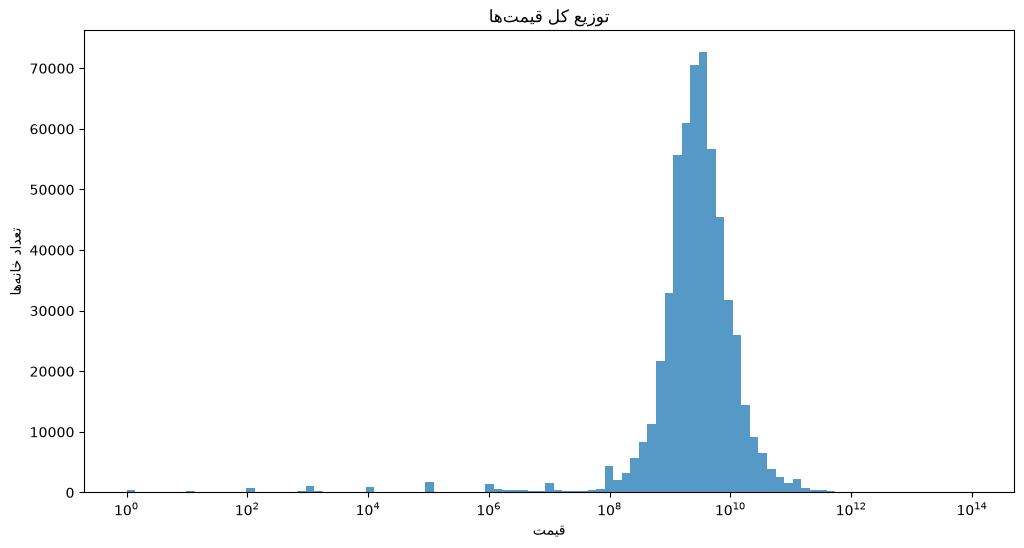

In [15]:
prices = divar_df.loc[ (divar_df['price_value'].notna()) & (divar_df['price_value'] > 0), 'price_value' ]

bins = np.logspace(
    np.log10(prices.min()),
    np.log10(prices.max()),
    100
)

plt.figure(figsize=(12, 6))

sns.histplot(
    prices,
    bins=bins,
)

plt.xscale('log')
plt.xlabel('قیمت')
plt.ylabel('تعداد خانه‌ها')
plt.title( 'توزیع کل قیمت‌‌ها')

plt.show()

## all cat3_slug houses boxplot

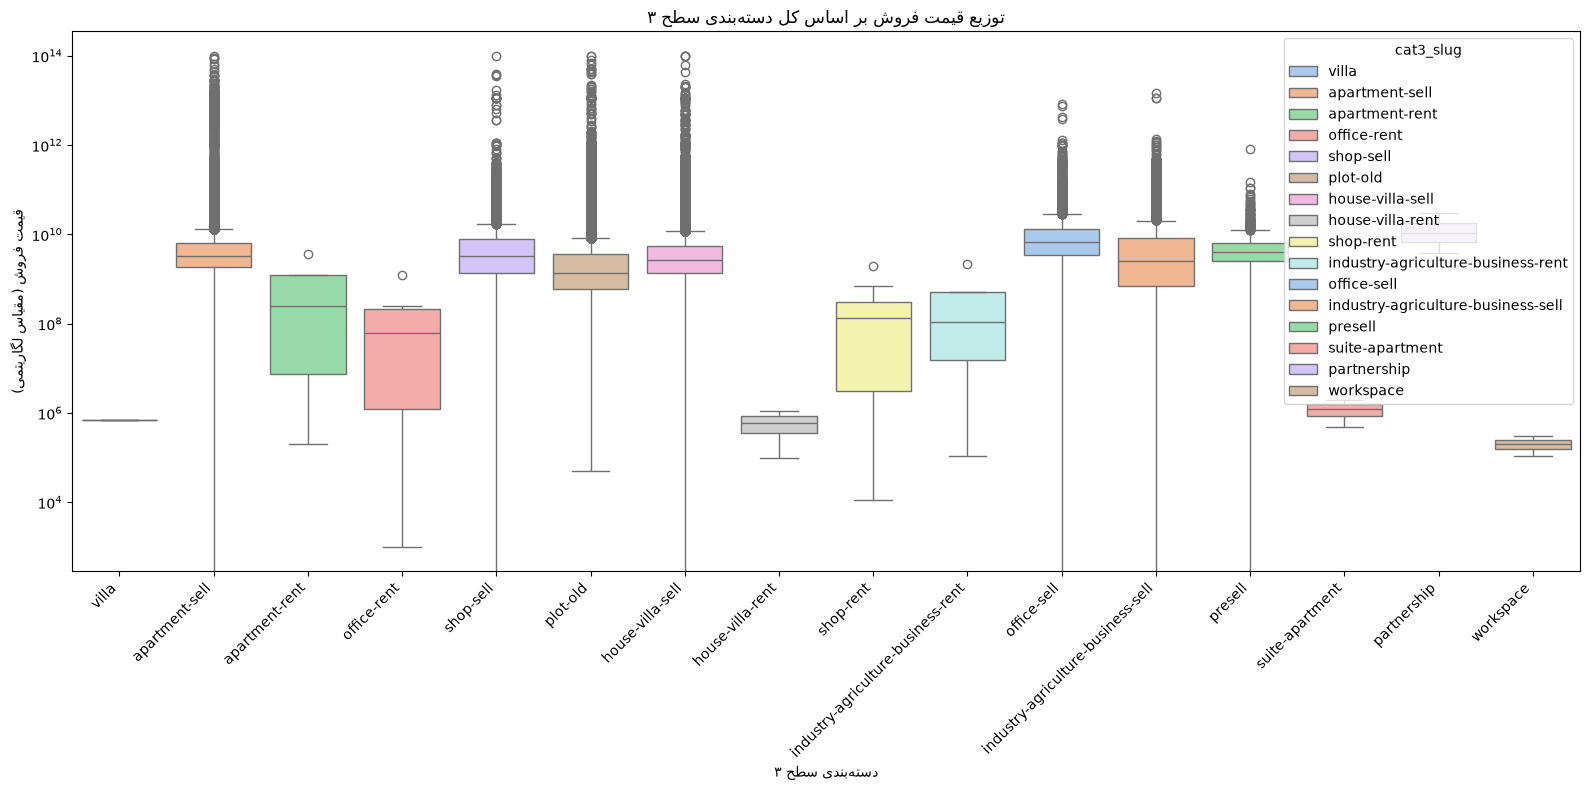

In [16]:
plt.figure(figsize=(16, 8))

sns.boxplot(
    data=divar_df,
    x='cat3_slug',
    y='price_value',
    hue='cat3_slug',
    palette='pastel'
)

plt.yscale('log')

plt.xticks(rotation=45, ha='right')
plt.xlabel('دسته‌بندی سطح ۳')
plt.ylabel('قیمت فروش (مقیاس لگاریتمی)')
plt.title('توزیع قیمت فروش بر اساس کل دسته‌بندی سطح ۳')

plt.tight_layout()
plt.show()

### some subcategories have very few ads.

In [17]:
slug_3_group_by = divar_df.groupby('cat3_slug')['price_value'].agg(
    'count'
)
slug_3_group_by

cat3_slug
apartment-rent                             4
apartment-sell                        303380
house-villa-rent                           2
house-villa-sell                      121748
industry-agriculture-business-rent         5
industry-agriculture-business-sell      9088
office-rent                                6
office-sell                             4480
partnership                                6
plot-old                              109836
presell                                 1204
shop-rent                                 23
shop-sell                              18559
suite-apartment                            2
villa                                      1
workspace                                  2
Name: price_value, dtype: int64

In [18]:
cat3_slug_greater_than_20 = slug_3_group_by[slug_3_group_by > 20]
cat3_slug_greater_than_20.index

Index(['apartment-sell', 'house-villa-sell',
       'industry-agriculture-business-sell', 'office-sell', 'plot-old',
       'presell', 'shop-rent', 'shop-sell'],
      dtype='str', name='cat3_slug')

### plotting those with number of ads => 20

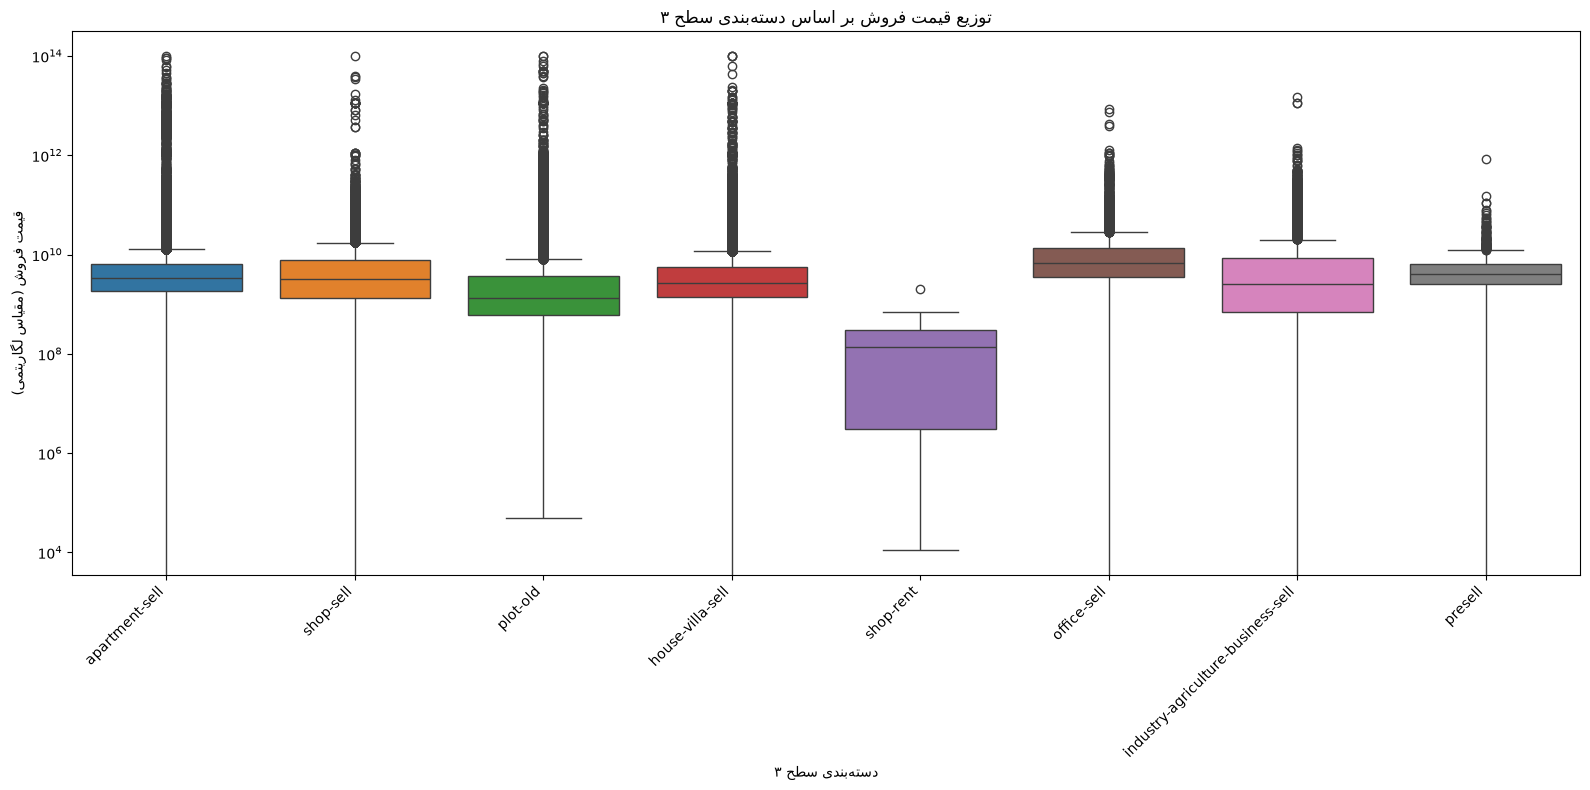

In [19]:
plt.figure(figsize=(16, 8))

valid_subcategories = slug_3_group_by[slug_3_group_by >= 20].index
df_filtered = divar_df[divar_df['cat3_slug'].isin(valid_subcategories)]

sns.boxplot(
    data=df_filtered,
    x='cat3_slug',
    y='price_value',
    hue='cat3_slug'
)

plt.yscale('log')

plt.xticks(rotation=45, ha='right')
plt.xlabel('دسته‌بندی سطح ۳')
plt.ylabel('قیمت فروش (مقیاس لگاریتمی)')
plt.title('توزیع قیمت فروش بر اساس دسته‌بندی سطح ۳')

plt.tight_layout()
plt.show()

### plotting with restrictions on price_value

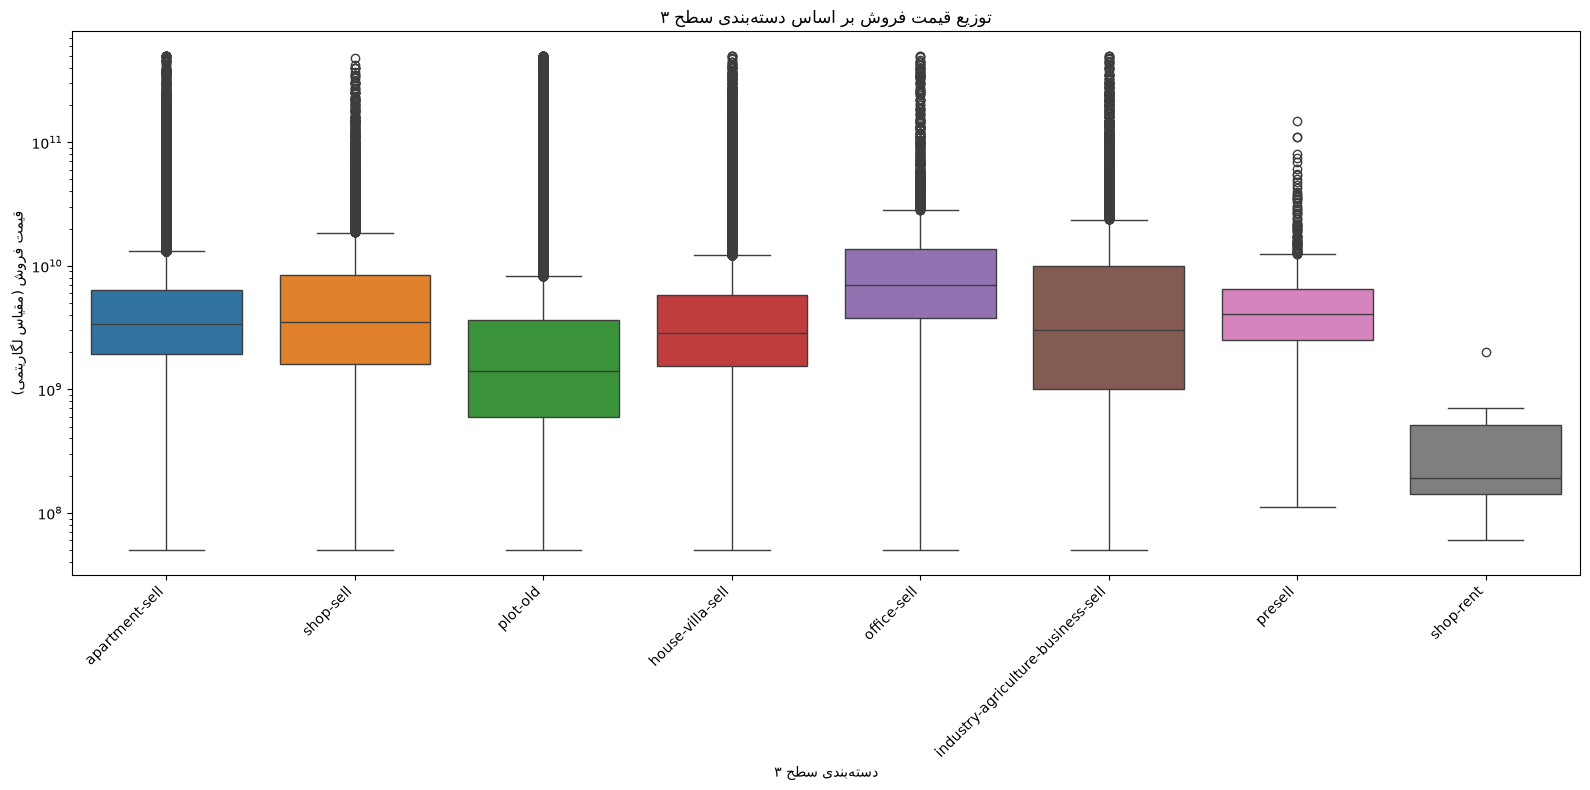

In [20]:
plt.figure(figsize=(16, 8))

valid_subcategories = slug_3_group_by[slug_3_group_by >= 20].index

min_price = 50_000_000
max_price = 500_000_000_000

new_df = divar_df
new_df['price_value'].dropna()
new_df = new_df[(new_df['cat3_slug'].isin(valid_subcategories)) & 
                  ( (new_df['price_value'] >= min_price) & (new_df['price_value'] <= max_price))]

sns.boxplot(
    data=new_df,
    x='cat3_slug',
    y='price_value',
    hue='cat3_slug'
)

plt.yscale('log')

plt.xticks(rotation=45, ha='right')
plt.xlabel('دسته‌بندی سطح ۳')
plt.ylabel('قیمت فروش (مقیاس لگاریتمی)')
plt.title('توزیع قیمت فروش بر اساس دسته‌بندی سطح ۳')

plt.tight_layout()
plt.show()


 ### histogram of the new dataframe prices

<Axes: xlabel='price_value', ylabel='Count'>

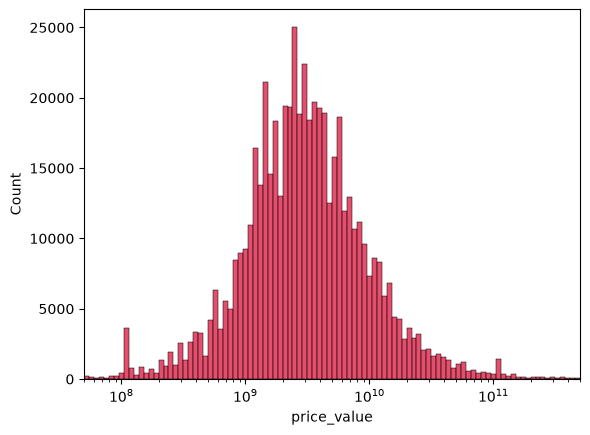

In [21]:

plt.xscale('log')
plt.xlim(new_df['price_value'].min(), new_df['price_value'].max())
sns.histplot(
    data=new_df,
    x='price_value',
    bins=100,
    color='crimson',
)